<a href="https://colab.research.google.com/github/em2tech/Machine_Learning_SJU/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Heart Disease Classification with SVC and Decision Trees**

This notebook walks through a complete, reproducible machine-learning workflow for predicting the presence of heart disease.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, roc_curve, accuracy_score, f1_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

**Task 1: Load the Dataset into a Pandas DataFrame by bringing the raw UCI Disease(cleveland) data into a pandas.DataFrame.**

In [2]:
COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]
UCI_URL = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
           "heart-disease/processed.cleveland.data")

try:
    df_raw = pd.read_csv(UCI_URL, header=None, names=COLUMNS)
    print("Loaded data directly from the UCI repository.")
except Exception as e:
    print(f"Could not reach UCI ({type(e).__name__}); loading local copy instead.")
    df_raw = pd.read_csv("processed.cleveland.data", header=None, names=COLUMNS)

# Binary target: 0 = no disease, 1 = disease present (num 1-4)
df = df_raw.copy()
df["target"] = (df["num"] > 0).astype(int)
df = df.drop(columns="num")

print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Loaded data directly from the UCI repository.
Shape: 303 rows x 14 columns


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


**2. Task 2: Structual Inspection with head(), info(), and describe(). The goal is to understand what the data looks like before modelling.**

In [3]:
print("=== head() ===")
display(df.head(10))

print("\n=== info() ===")
df.info()

print("\n=== describe() — numeric columns ===")
display(df.describe().T.round(2))

continuous = ["age", "trestbps", "chol", "thalach", "oldpeak"]
print("\n=== Skewness of continuous features ===")
print(df[continuous].skew().round(3))

categorical_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
print("\n=== Value counts for categorical columns ===")
for c in categorical_cols:
    print(f"{c}: {df[c].value_counts().sort_index().to_dict()}")

print("\n=== Class balance (target) ===")
print(df["target"].value_counts().rename({0: "No disease (0)", 1: "Disease (1)"}))
print(df["target"].value_counts(normalize=True).round(3))

=== head() ===


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
5,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0
6,62.0,0.0,4.0,140.0,268.0,0.0,2.0,160.0,0.0,3.6,3.0,2.0,3.0,1
7,57.0,0.0,4.0,120.0,354.0,0.0,0.0,163.0,1.0,0.6,1.0,0.0,3.0,0
8,63.0,1.0,4.0,130.0,254.0,0.0,2.0,147.0,0.0,1.4,2.0,1.0,7.0,1
9,53.0,1.0,4.0,140.0,203.0,1.0,2.0,155.0,1.0,3.1,3.0,0.0,7.0,1



=== info() ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        303 non-null    object 
 12  thal      303 non-null    object 
 13  target    303 non-null    int64  
dtypes: float64(11), int64(1), object(2)
memory usage: 33.3+ KB

=== describe() — numeric columns ===


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2



=== Skewness of continuous features ===
age        -0.209
trestbps    0.706
chol        1.136
thalach    -0.537
oldpeak     1.270
dtype: float64

=== Value counts for categorical columns ===
sex: {0.0: 97, 1.0: 206}
cp: {1.0: 23, 2.0: 50, 3.0: 86, 4.0: 144}
fbs: {0.0: 258, 1.0: 45}
restecg: {0.0: 151, 1.0: 4, 2.0: 148}
exang: {0.0: 204, 1.0: 99}
slope: {1.0: 142, 2.0: 140, 3.0: 21}
ca: {'0.0': 176, '1.0': 65, '2.0': 38, '3.0': 20, '?': 4}
thal: {'3.0': 166, '6.0': 18, '7.0': 117, '?': 2}

=== Class balance (target) ===
target
No disease (0)    164
Disease (1)       139
Name: count, dtype: int64
target
0    0.541
1    0.459
Name: proportion, dtype: float64


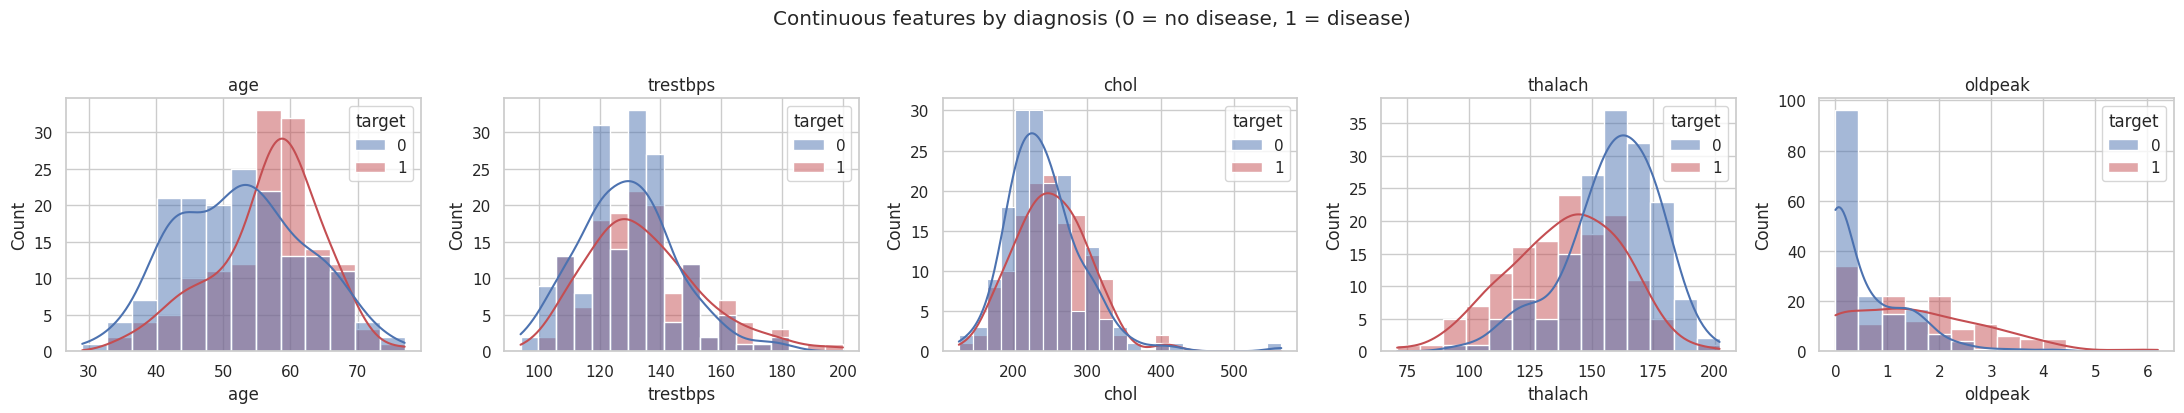

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, continuous):
    sns.histplot(data=df, x=col, hue="target", kde=True, ax=ax, palette={0: "#4C72B0", 1: "#C44E52"})
    ax.set_title(col)
plt.suptitle("Continuous features by diagnosis (0 = no disease, 1 = disease)", y=1.03)
plt.tight_layout()
plt.show()

**Task 3:Quantify and Handle Hidden Missing Values with SimpleImputer. This task finds missing entries that are masked as legitimate values and then applies a well-adjusted imputation strategy to fill them.**



In [5]:
# 1) Standard null check BEFORE cleaning — the '?' strings are invisible to it
print("isnull() count before cleaning:", int(df.isnull().sum().sum()))

# 2) Scan every column for the '?' placeholder
q_counts = (df.astype(str) == "?").sum()
print("\n'?' placeholders per column:")
print(q_counts[q_counts > 0])
print(f"Total '?' cells: {int(q_counts.sum())}  |  rows affected: {int((df.astype(str) == '?').any(axis=1).sum())}")

# 3) Convert placeholders to real NaN and coerce to numeric dtype
df = df.replace("?", np.nan)
for c in ["ca", "thal"]:
    df[c] = pd.to_numeric(df[c])

missing = df.isnull().sum()
print("\nTrue missing values after conversion:")
print(pd.DataFrame({"missing": missing, "pct": (missing / len(df) * 100).round(2)})[missing > 0])
print("\nRows with missing values:")
display(df[df.isnull().any(axis=1)])

isnull() count before cleaning: 0

'?' placeholders per column:
ca      4
thal    2
dtype: int64
Total '?' cells: 6  |  rows affected: 6

True missing values after conversion:
      missing   pct
ca          4  1.32
thal        2  0.66

Rows with missing values:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
87,53.0,0.0,3.0,128.0,216.0,0.0,2.0,115.0,0.0,0.0,1.0,0.0,NaN,0
166,52.0,1.0,3.0,138.0,223.0,0.0,0.0,169.0,0.0,0.0,1.0,NaN,3.0,0
192,43.0,1.0,4.0,132.0,247.0,1.0,2.0,143.0,1.0,0.1,2.0,NaN,7.0,1
266,52.0,1.0,4.0,128.0,204.0,1.0,0.0,156.0,1.0,1.0,2.0,0.0,NaN,1
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0


In [6]:
# 4) Demonstrate the imputation strategy (the pipeline in Task 4 re-learns these from the TRAINING data only)
numeric_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

df_imputed = df.copy()
df_imputed[numeric_features] = num_imputer.fit_transform(df[numeric_features])
df_imputed[categorical_features] = cat_imputer.fit_transform(df[categorical_features])

print("Median used per numeric feature:", dict(zip(numeric_features, num_imputer.statistics_)))
print("Mode used per categorical feature:", dict(zip(categorical_features, cat_imputer.statistics_)))
print("\nMissing values remaining after imputation:", int(df_imputed.isnull().sum().sum()))

Median used per numeric feature: {'age': np.float64(56.0), 'trestbps': np.float64(130.0), 'chol': np.float64(241.0), 'thalach': np.float64(153.0), 'oldpeak': np.float64(0.8)}
Mode used per categorical feature: {'sex': np.float64(1.0), 'cp': np.float64(4.0), 'fbs': np.float64(0.0), 'restecg': np.float64(0.0), 'exang': np.float64(0.0), 'slope': np.float64(1.0), 'ca': np.float64(0.0), 'thal': np.float64(3.0)}

Missing values remaining after imputation: 0


**Task 4: Isolate Feature Types and Build the ColumnTransformer + pipeline. This task creates one reusable preprocessing object that treats each feature type correctly and can be attached to any classifier.**

In [7]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print("Disease prevalence — train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

# Inspect what the preprocessor produces
X_train_t = preprocessor.fit_transform(X_train)
feature_names = preprocessor.get_feature_names_out()
print(f"\nFeatures after preprocessing: {X_train_t.shape[1]}")
print(list(feature_names))
pd.DataFrame(X_train_t[:5], columns=feature_names).round(2)

Train: (242, 13), Test: (61, 13)
Disease prevalence — train: 0.459 | test: 0.459

Features after preprocessing: 25
['num__age', 'num__trestbps', 'num__chol', 'num__thalach', 'num__oldpeak', 'cat__sex_1.0', 'cat__cp_1.0', 'cat__cp_2.0', 'cat__cp_3.0', 'cat__cp_4.0', 'cat__fbs_1.0', 'cat__restecg_0.0', 'cat__restecg_1.0', 'cat__restecg_2.0', 'cat__exang_1.0', 'cat__slope_1.0', 'cat__slope_2.0', 'cat__slope_3.0', 'cat__ca_0.0', 'cat__ca_1.0', 'cat__ca_2.0', 'cat__ca_3.0', 'cat__thal_3.0', 'cat__thal_6.0', 'cat__thal_7.0']


,num__age,num__trestbps,num__chol,num__thalach,num__oldpeak,cat__sex_1.0,cat__cp_1.0,cat__cp_2.0,cat__cp_3.0,cat__cp_4.0,cat__fbs_1.0,cat__restecg_0.0,cat__restecg_1.0,cat__restecg_2.0,cat__exang_1.0,cat__slope_1.0,cat__slope_2.0,cat__slope_3.0,cat__ca_0.0,cat__ca_1.0,cat__ca_2.0,cat__ca_3.0,cat__thal_3.0,cat__thal_6.0,cat__thal_7.0
0,-0.73,-0.40,0.46,0.71,-0.45,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.05,-0.05,0.23,0.22,-0.89,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-0.06,0.06,0.72,0.40,-0.89,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,-0.06,-1.31,1.12,0.27,-0.89,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.27,0.51,-0.17,-1.19,-0.71,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


**Task 5: Trian and Evaluate an RBF-Kernel Support Vector Classifier**
This task fit an SVC(Kernerl="rbf", provablity=True) inside the preprocessing pipleline and evaluate it thouroughly.

===== SVC (RBF, default) =====
Train accuracy: 0.909
Test accuracy:  0.885
Test ROC-AUC:   0.963
5-fold CV ROC-AUC (train): 0.883 ± 0.023

              precision    recall  f1-score   support

  No disease      0.933     0.848     0.889        33
     Disease      0.839     0.929     0.881        28

    accuracy                          0.885        61
   macro avg      0.886     0.889     0.885        61
weighted avg      0.890     0.885     0.885        61



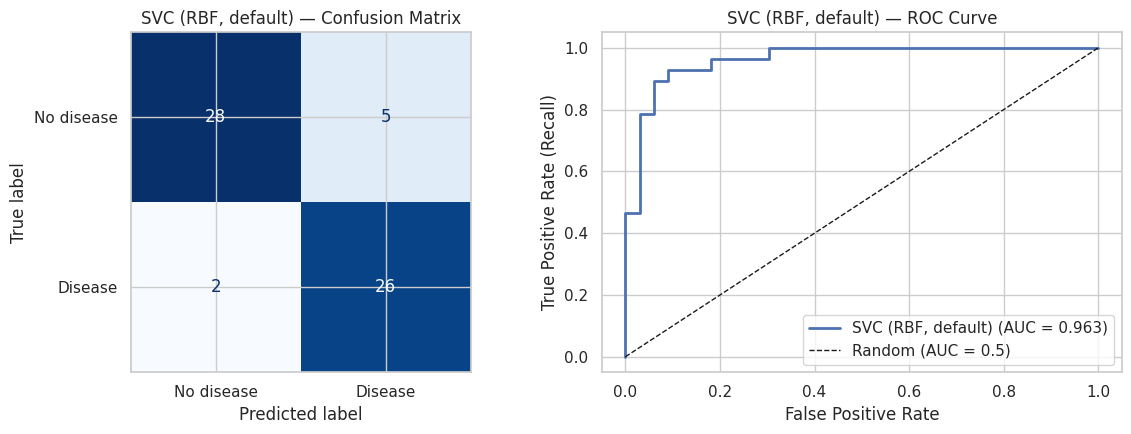

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = {}

def evaluate_model(name, pipe):
    # Fit on training data, then report CM, classification report, ROC-AUC on the test set.
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_prob)
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")

    print(f"===== {name} =====")
    print(f"Train accuracy: {accuracy_score(y_train, pipe.predict(X_train)):.3f}")
    print(f"Test accuracy:  {accuracy_score(y_test, y_pred):.3f}")
    print(f"Test ROC-AUC:   {auc:.3f}")
    print(f"5-fold CV ROC-AUC (train): {cv_auc.mean():.3f} ± {cv_auc.std():.3f}\n")
    print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"], digits=3))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["No disease", "Disease"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
    axes[0].set_title(f"{name} — Confusion Matrix")
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    axes[1].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc:.3f})")
    axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Random (AUC = 0.5)")
    axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate (Recall)")
    axes[1].set_title(f"{name} — ROC Curve"); axes[1].legend(loc="lower right")
    plt.tight_layout(); plt.show()

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    results[name] = {"Train acc": accuracy_score(y_train, pipe.predict(X_train)),
                     "Test acc": accuracy_score(y_test, y_pred),
                     "Test F1 (disease)": f1_score(y_test, y_pred),
                     "Test ROC-AUC": auc, "CV ROC-AUC": cv_auc.mean(),
                     "False negatives": fn, "False positives": fp,
                     "fpr": fpr, "tpr": tpr}
    return pipe

svc_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
])
svc_pipe = evaluate_model("SVC (RBF, default)", svc_pipe)

**Task 6: Train and Evaluate a Decision Tree Classifier**
This task train a DecisionTreeClassifier in the same preprocessing pipeline and evaluate it with identical metrics so the comparison with the SVC is fair.

===== Decision Tree (default) =====
Train accuracy: 1.000
Test accuracy:  0.754
Test ROC-AUC:   0.762
5-fold CV ROC-AUC (train): 0.675 ± 0.060

              precision    recall  f1-score   support

  No disease      0.846     0.667     0.746        33
     Disease      0.686     0.857     0.762        28

    accuracy                          0.754        61
   macro avg      0.766     0.762     0.754        61
weighted avg      0.773     0.754     0.753        61



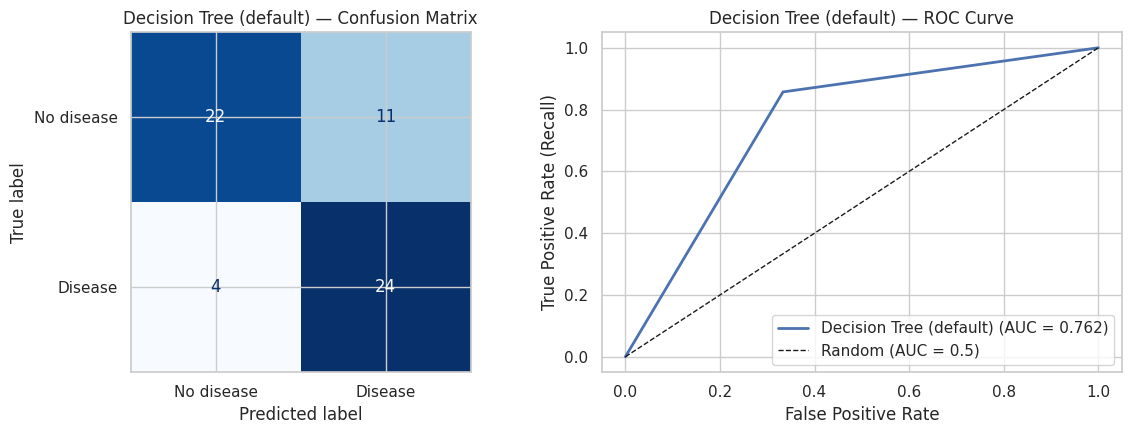

Tree depth: 9 | leaves: 47


In [9]:
tree_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])
tree_pipe = evaluate_model("Decision Tree (default)", tree_pipe)
print("Tree depth:", tree_pipe.named_steps["classifier"].get_depth(),
      "| leaves:", tree_pipe.named_steps["classifier"].get_n_leaves())

,Train acc,Test acc,Test F1 (disease),Test ROC-AUC,CV ROC-AUC,False negatives,False positives
"SVC (RBF, default)",0.909,0.885,0.881,0.963,0.883,2.0,5.0
Decision Tree (default),1.000,0.754,0.762,0.762,0.675,4.0,11.0


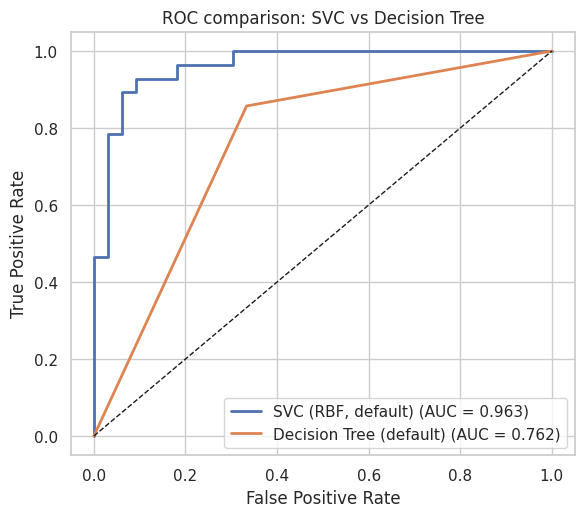

In [10]:
def comparison_table():
    return pd.DataFrame({k: {m: v for m, v in r.items() if m not in ("fpr", "tpr")}
                         for k, r in results.items()}).T.round(3)

display(comparison_table())

plt.figure(figsize=(6.5, 5.5))
for name, r in results.items():
    plt.plot(r["fpr"], r["tpr"], lw=2, label=f"{name} (AUC = {r['Test ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC comparison: SVC vs Decision Tree"); plt.legend(loc="lower right")
plt.show()

**Task 7: Hyperparameter Tuning of the SVC with GridSearchCV**
This task will find the combination of C and gamma that maximises cross-validated performance, using only the training data.

Best parameters: {'classifier__C': 100, 'classifier__gamma': 0.001}
Best mean CV ROC-AUC: 0.907


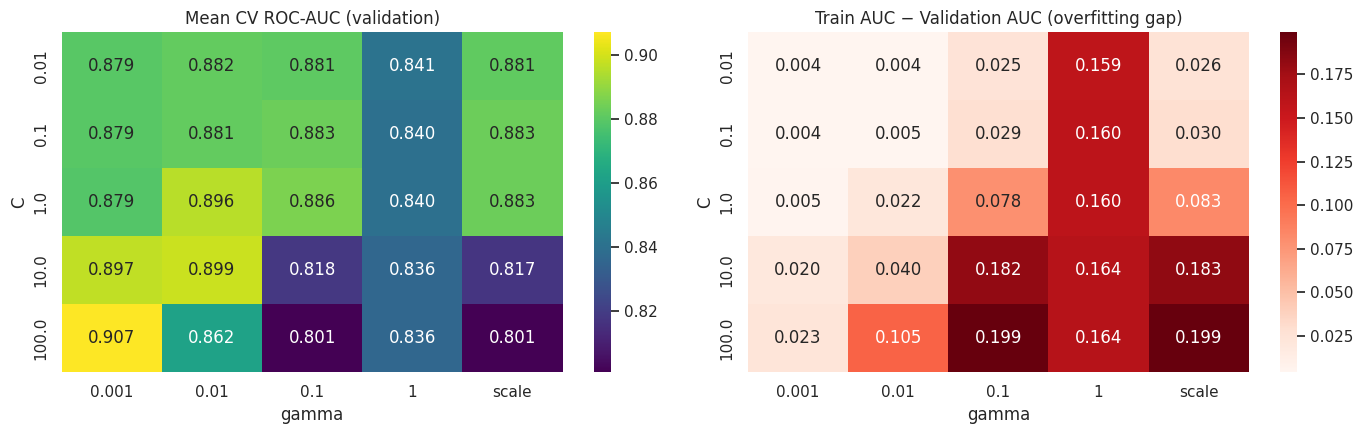

In [11]:
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__gamma": [0.001, 0.01, 0.1, 1, "scale"],
}
svc_base = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
])
grid = GridSearchCV(svc_base, param_grid, cv=cv, scoring="roc_auc",
                    n_jobs=-1, refit=True, return_train_score=True)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print(f"Best mean CV ROC-AUC: {grid.best_score_:.3f}")

cvres = pd.DataFrame(grid.cv_results_)
cvres["gamma"] = cvres["param_classifier__gamma"].astype(str)
cvres["C"] = cvres["param_classifier__C"]
heat = cvres.pivot(index="C", columns="gamma", values="mean_test_score")
heat = heat[["0.001", "0.01", "0.1", "1", "scale"]]
gap = cvres.pivot(index="C", columns="gamma", values="mean_train_score")[heat.columns] - heat

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="viridis", ax=axes[0])
axes[0].set_title("Mean CV ROC-AUC (validation)")
sns.heatmap(gap, annot=True, fmt=".3f", cmap="Reds", ax=axes[1])
axes[1].set_title("Train AUC − Validation AUC (overfitting gap)")
plt.tight_layout(); plt.show()

===== SVC (tuned) =====
Train accuracy: 0.847
Test accuracy:  0.836
Test ROC-AUC:   0.947
5-fold CV ROC-AUC (train): 0.907 ± 0.018

              precision    recall  f1-score   support

  No disease      0.871     0.818     0.844        33
     Disease      0.800     0.857     0.828        28

    accuracy                          0.836        61
   macro avg      0.835     0.838     0.836        61
weighted avg      0.838     0.836     0.836        61



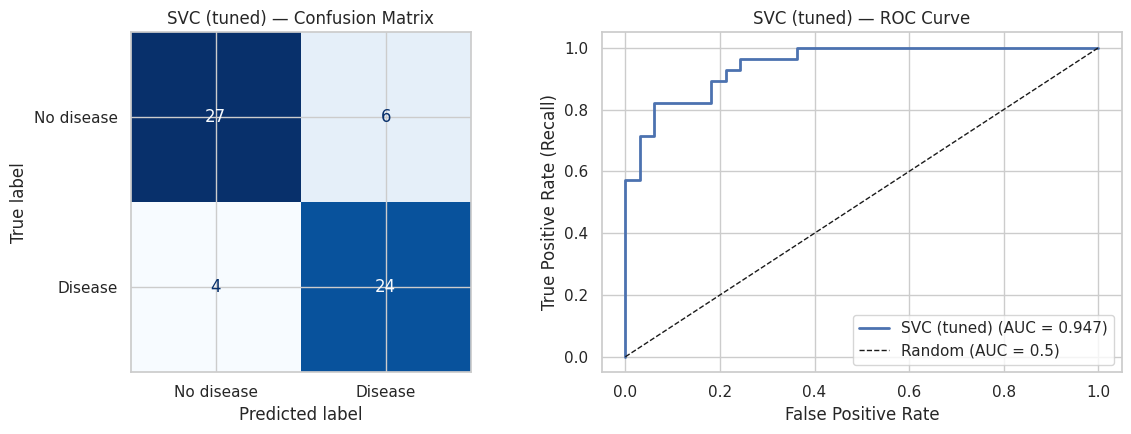

,Train acc,Test acc,Test F1 (disease),Test ROC-AUC,CV ROC-AUC,False negatives,False positives
"SVC (RBF, default)",0.909,0.885,0.881,0.963,0.883,2.0,5.0
Decision Tree (default),1.000,0.754,0.762,0.762,0.675,4.0,11.0
SVC (tuned),0.847,0.836,0.828,0.947,0.907,4.0,6.0


In [12]:
best_svc = evaluate_model("SVC (tuned)", grid.best_estimator_)
display(comparison_table())

**Task 8: Interpret the Decision Tree and Feature Importances**
This task explains how the models sepearte patients with heart disease from healthy patients.

Best pruned-tree parameters: {'classifier__max_depth': 4, 'classifier__min_samples_leaf': 20}
Best mean CV ROC-AUC: 0.855

===== Decision Tree (pruned) =====
Train accuracy: 0.773
Test accuracy:  0.770
Test ROC-AUC:   0.845
5-fold CV ROC-AUC (train): 0.855 ± 0.011

              precision    recall  f1-score   support

  No disease      0.721     0.939     0.816        33
     Disease      0.889     0.571     0.696        28

    accuracy                          0.770        61
   macro avg      0.805     0.755     0.756        61
weighted avg      0.798     0.770     0.761        61



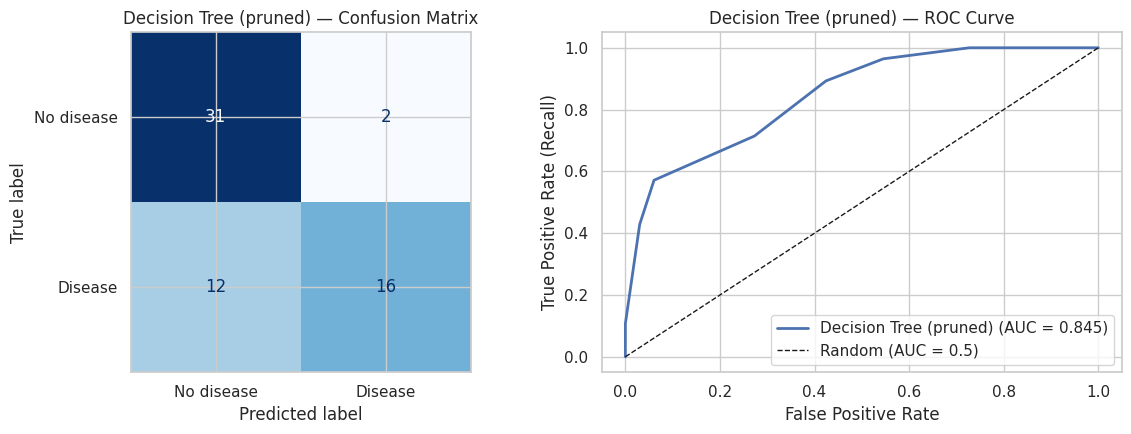

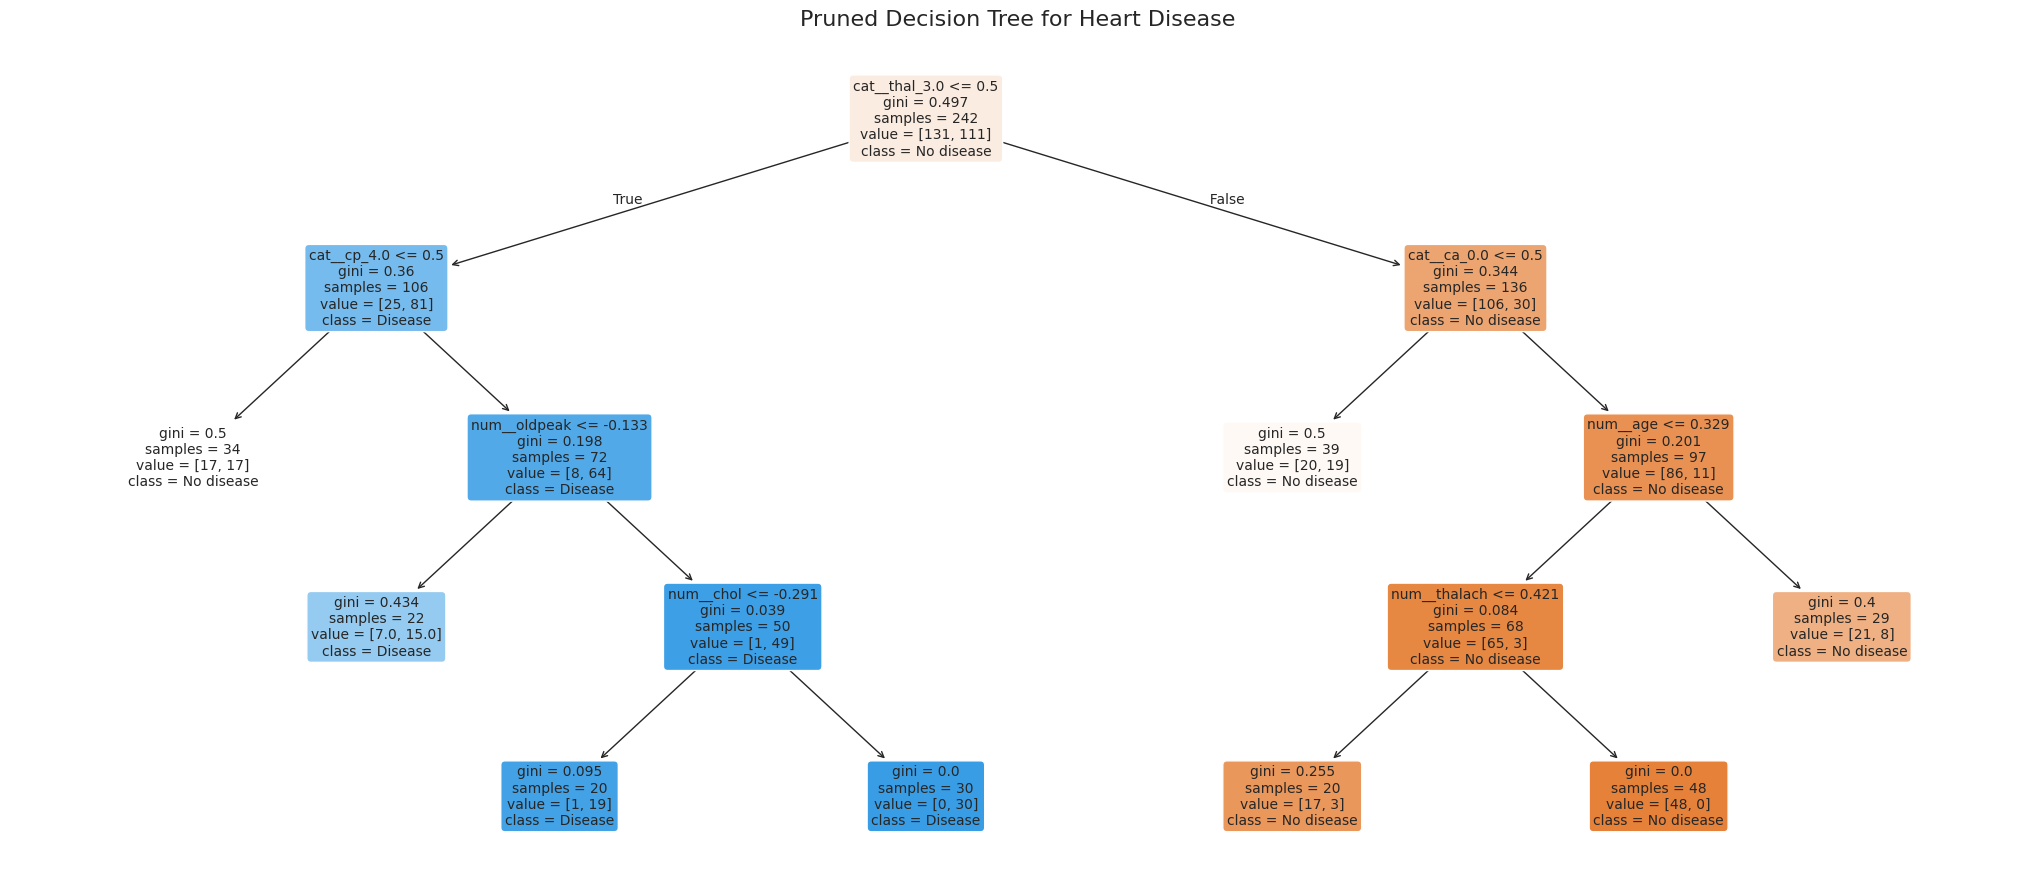

In [13]:
tree_grid = GridSearchCV(
    Pipeline([("preprocessor", preprocessor),
              ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    {"classifier__max_depth": [2, 3, 4, 5, 6],
     "classifier__min_samples_leaf": [1, 5, 10, 20]},
    cv=cv, scoring="roc_auc", n_jobs=-1)
tree_grid.fit(X_train, y_train)
print("Best pruned-tree parameters:", tree_grid.best_params_)
print(f"Best mean CV ROC-AUC: {tree_grid.best_score_:.3f}\n")
pruned_tree = evaluate_model("Decision Tree (pruned)", tree_grid.best_estimator_)

clf = pruned_tree.named_steps["classifier"]
plt.figure(figsize=(26, 11))
plot_tree(clf, feature_names=feature_names, class_names=["No disease", "Disease"],
          filled=True, rounded=True, fontsize=10, impurity=True, proportion=False)
plt.title("Pruned Decision Tree for Heart Disease", fontsize=16)
plt.show()

,Tree (full) Gini,Tree (pruned) Gini,Tuned SVC permutation (AUC drop)
thal,0.301,0.634,0.017
cp,0.132,0.126,0.032
ca,0.112,0.140,0.053
chol,0.107,0.001,-0.000
age,0.106,0.039,0.001
oldpeak,0.081,0.049,0.018
thalach,0.050,0.011,0.006
slope,0.029,0.000,0.007
trestbps,0.028,0.000,0.006
sex,0.021,0.000,-0.001


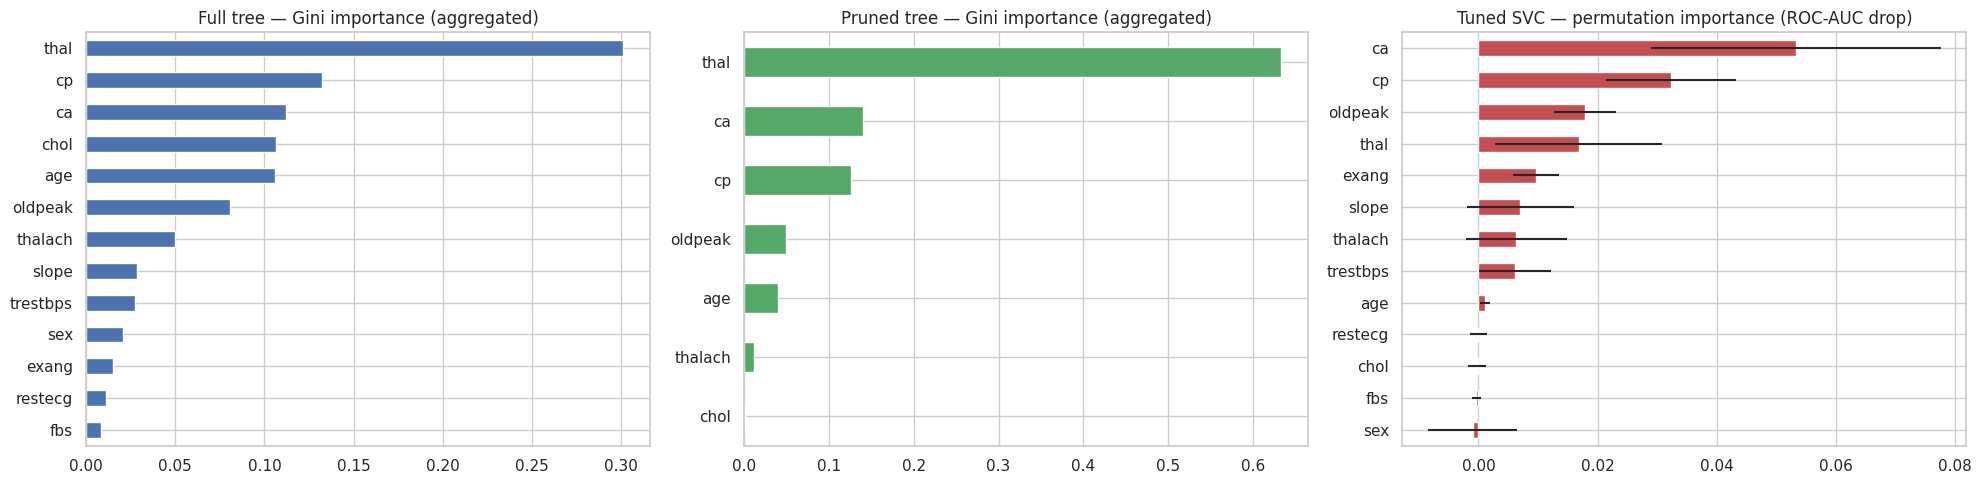

In [14]:
def aggregate(importances, names):
    # Map one-hot column names (e.g. 'cat__cp_4.0') back to the clinical feature ('cp').
    s = pd.Series(importances, index=names)
    base = [n.split("__", 1)[1] for n in names]
    base = [b if b in numeric_features else b.rsplit("_", 1)[0] for b in base]
    return s.groupby(base).sum().sort_values(ascending=False)

full_tree = tree_pipe.named_steps["classifier"]
tree_imp_full = aggregate(full_tree.feature_importances_, feature_names)
tree_imp_pruned = aggregate(clf.feature_importances_, feature_names)

perm = permutation_importance(best_svc, X_test, y_test, scoring="roc_auc",
                              n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
svc_perm = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

imp_table = pd.DataFrame({"Tree (full) Gini": tree_imp_full,
                          "Tree (pruned) Gini": tree_imp_pruned,
                          "Tuned SVC permutation (AUC drop)": svc_perm}).fillna(0)
imp_table = imp_table.sort_values("Tree (full) Gini", ascending=False).round(3)
display(imp_table)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
tree_imp_full.sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Full tree — Gini importance (aggregated)")
tree_imp_pruned[tree_imp_pruned > 0].sort_values().plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title("Pruned tree — Gini importance (aggregated)")
svc_perm.sort_values().plot.barh(ax=axes[2], color="#C44E52",
                                 xerr=pd.Series(perm.importances_std, index=X_test.columns)[svc_perm.sort_values().index])
axes[2].set_title("Tuned SVC — permutation importance (ROC-AUC drop)")
plt.tight_layout(); plt.show()

In [15]:
# How do the top indicators differ between the two groups?
summary = df.groupby("target")[["thalach", "oldpeak", "age", "chol", "trestbps"]].mean().round(1)
summary.index = ["No disease", "Disease"]
display(summary)
for c in ["cp", "thal", "ca", "exang", "slope"]:
    print(f"\nDisease rate by {c}:")
    print(df.groupby(c)["target"].agg(["mean", "count"]).rename(columns={"mean": "disease_rate"}).round(2))

,thalach,oldpeak,age,chol,trestbps
No disease,158.4,0.6,52.6,242.6,129.2
Disease,139.3,1.6,56.6,251.5,134.6



Disease rate by cp:
     disease_rate  count
cp                      
1.0          0.30     23
2.0          0.18     50
3.0          0.21     86
4.0          0.73    144

Disease rate by thal:
      disease_rate  count
thal                     
3.0           0.22    166
6.0           0.67     18
7.0           0.76    117

Disease rate by ca:
     disease_rate  count
ca                      
0.0          0.26    176
1.0          0.68     65
2.0          0.82     38
3.0          0.85     20

Disease rate by exang:
       disease_rate  count
exang                     
0.0            0.31    204
1.0            0.77     99

Disease rate by slope:
       disease_rate  count
slope                     
1.0            0.25    142
2.0            0.65    140
3.0            0.57     21


In [16]:
final = comparison_table()
display(final)

,Train acc,Test acc,Test F1 (disease),Test ROC-AUC,CV ROC-AUC,False negatives,False positives
"SVC (RBF, default)",0.909,0.885,0.881,0.963,0.883,2.0,5.0
Decision Tree (default),1.000,0.754,0.762,0.762,0.675,4.0,11.0
SVC (tuned),0.847,0.836,0.828,0.947,0.907,4.0,6.0
Decision Tree (pruned),0.773,0.770,0.696,0.845,0.855,12.0,2.0
